In [ ]:
# !pip install matplotlib 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

In [2]:
file_path = '../../03_GWAS_Pure/14_Regression_local/08_001_1e6_10_LT_GOTERM_BP_DIRECT.txt'
file_path2 = '../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_GOTERM_CC_DIRECT.txt'
file_path3 = '../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_GOTERM_MF_DIRECT.txt'
file_path4 = '../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_KEGG_PATHWAY.txt'

In [10]:
def standardize_david_columns(df):
    """DAVID 출력 컬럼명을 표준화 (P-Value/PValue, User Ids/Genes 등 변형에 대응)"""
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]

    # 공백/하이픈/언더스코어 제거하고 소문자로 변환해서 매칭
    def normalize(name):
        return name.replace(" ", "").replace("-", "").replace("_", "").lower()

    rename_map = {}
    for col in df.columns:
        norm = normalize(col)
        if norm == "pvalue":
            rename_map[col] = "PValue"
        elif norm == "userids" or norm == "genes":
            rename_map[col] = "Genes"
        elif norm == "listtotal":
            rename_map[col] = "List.Total"

    df = df.rename(columns=rename_map)
    return df

In [13]:
bp_df = standardize_david_columns(pd.read_csv(file_path, sep='\t'))
cc_df = standardize_david_columns(pd.read_csv(file_path2, sep='\t'))
mf_df = standardize_david_columns(pd.read_csv(file_path3, sep='\t'))
kegg_df = standardize_david_columns(pd.read_csv(file_path4, sep='\t'))

In [11]:
def filtered_terms(df, category_label, term_col="Term", pval_col="PValue", pval_threshold=0.05):
    df_filtered = df[df[pval_col] < pval_threshold].copy()
    df_filtered["Category_Label"] = category_label
    return df_filtered[[term_col, pval_col, "Genes", "Category_Label"]]

In [14]:
filtered_bp = filtered_terms(bp_df, "Biological Process")
filtered_bp

,Term,PValue,Genes,Category_Label
0,nervous system development,0.00156,"ENSCAFG00000005535,ENSCAFG00000015135,ENSCAFG0...",Biological Process
1,regulation of smoothened signaling pathway,0.00452,"ENSCAFG00000032695,ENSCAFG00000007436,ENSCAFG0...",Biological Process
2,positive regulation of transcription by RNA po...,0.01300,"ENSCAFG00000015135,ENSCAFG00000005779,ENSCAFG0...",Biological Process
3,signal transduction,0.01380,"ENSCAFG00000013122,ENSCAFG00000005535,ENSCAFG0...",Biological Process
4,establishment of localization in cell,0.01980,"ENSCAFG00000012881,ENSCAFG00000010731,ENSCAFG0...",Biological Process
5,positive regulation of adenylate cyclase-activ...,0.02230,"ENSCAFG00000004882,ENSCAFG00000009820",Biological Process
6,negative regulation of monocyte chemotactic pr...,0.02780,"ENSCAFG00000018825,ENSCAFG00000002634",Biological Process
7,nitric oxide mediated signal transduction,0.02780,"ENSCAFG00000014739,ENSCAFG00000009820",Biological Process
8,sensory perception of sound,0.03280,"ENSCAFG00000004294,ENSCAFG00000010731,ENSCAFG0...",Biological Process
9,cell differentiation,0.03340,"ENSCAFG00000007418,ENSCAFG00000004535,ENSCAFG0...",Biological Process


In [15]:
filtered_cc = filtered_terms(cc_df, "Cellular Component")
filtered_cc

,Term,PValue,Genes,Category_Label
0,dendritic spine,0.000298,"ENSCAFG00000004315,ENSCAFG00000001380,ENSCAFG0...",Cellular Component
1,postsynaptic membrane,0.002290,"ENSCAFG00000018508,ENSCAFG00000018839,ENSCAFG0...",Cellular Component
2,postsynaptic density membrane,0.013100,"ENSCAFG00000004315,ENSCAFG00000018839,ENSCAFG0...",Cellular Component
3,postsynaptic density,0.013800,"ENSCAFG00000001380,ENSCAFG00000018839,ENSCAFG0...",Cellular Component
4,dendrite,0.020500,"ENSCAFG00000018508,ENSCAFG00000001380,ENSCAFG0...",Cellular Component
5,cytoplasm,0.022500,"ENSCAFG00000013122,ENSCAFG00000013062,ENSCAFG0...",Cellular Component
6,glutamatergic synapse,0.024000,"ENSCAFG00000018508,ENSCAFG00000018839,ENSCAFG0...",Cellular Component
7,cytosol,0.028000,"ENSCAFG00000010292,ENSCAFG00000005161,ENSCAFG0...",Cellular Component
8,early endosome membrane,0.043000,"ENSCAFG00000004315,ENSCAFG00000007190,ENSCAFG0...",Cellular Component
9,axon,0.049900,"ENSCAFG00000004018,ENSCAFG00000018508,ENSCAFG0...",Cellular Component


In [16]:
filtered_kegg = filtered_terms(kegg_df, "KEGG Pathway")
filtered_kegg

,Term,PValue,Genes,Category_Label
0,Calcium signaling pathway,0.00233,"ENSCAFG00000001380,ENSCAFG00000032695,ENSCAFG0...",KEGG Pathway
1,beta-Alanine metabolism,0.01360,"ENSCAFG00000000588,ENSCAFG00000014554,ENSCAFG0...",KEGG Pathway
2,Circadian entrainment,0.01630,"ENSCAFG00000014739,ENSCAFG00000016051,ENSCAFG0...",KEGG Pathway
3,Propanoate metabolism,0.01780,"ENSCAFG00000006612,ENSCAFG00000014554,ENSCAFG0...",KEGG Pathway
4,Fatty acid degradation,0.02350,"ENSCAFG00000000588,ENSCAFG00000014554,ENSCAFG0...",KEGG Pathway
5,"Valine, leucine and isoleucine degradation",0.03090,"ENSCAFG00000000588,ENSCAFG00000018589,ENSCAFG0...",KEGG Pathway
6,Carbon metabolism,0.03440,"ENSCAFG00000006612,ENSCAFG00000014166,ENSCAFG0...",KEGG Pathway
7,Vascular smooth muscle contraction,0.03640,"ENSCAFG00000005779,ENSCAFG00000014739,ENSCAFG0...",KEGG Pathway
8,Long-term depression,0.04040,"ENSCAFG00000014739,ENSCAFG00000005760,ENSCAFG0...",KEGG Pathway
9,GnRH secretion,0.04550,"ENSCAFG00000018508,ENSCAFG00000016051,ENSCAFG0...",KEGG Pathway


In [17]:
filtered_mf = filtered_terms(mf_df, "Molecular Function")
filtered_mf

,Term,PValue,Genes,Category_Label
0,protein binding,0.00762,"ENSCAFG00000013122,ENSCAFG00000018825,ENSCAFG0...",Molecular Function
1,ATP binding,0.01030,"ENSCAFG00000013122,ENSCAFG00000005161,ENSCAFG0...",Molecular Function
2,heparin binding,0.04160,"ENSCAFG00000016608,ENSCAFG00000032695,ENSCAFG0...",Molecular Function
3,nuclear receptor activity,0.04370,"ENSCAFG00000004535,ENSCAFG00000008285,ENSCAFG0...",Molecular Function
4,alpha-actinin binding,0.04960,"ENSCAFG00000006722,ENSCAFG00000016051",Molecular Function


In [18]:
def plot_filtered_terms(df, title, color):
    df_sorted = df.sort_values(by="PValue")
    plt.figure(figsize=(10, max(6, len(df_sorted) * 0.4)))
    plt.barh(df_sorted["Term"], -np.log10(df_sorted["PValue"]), color=color)
    plt.xlabel('-log10(P-value)')
    plt.title(f'GO Terms (p < 0.05): {title}')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.grid(True)
    plt.show()

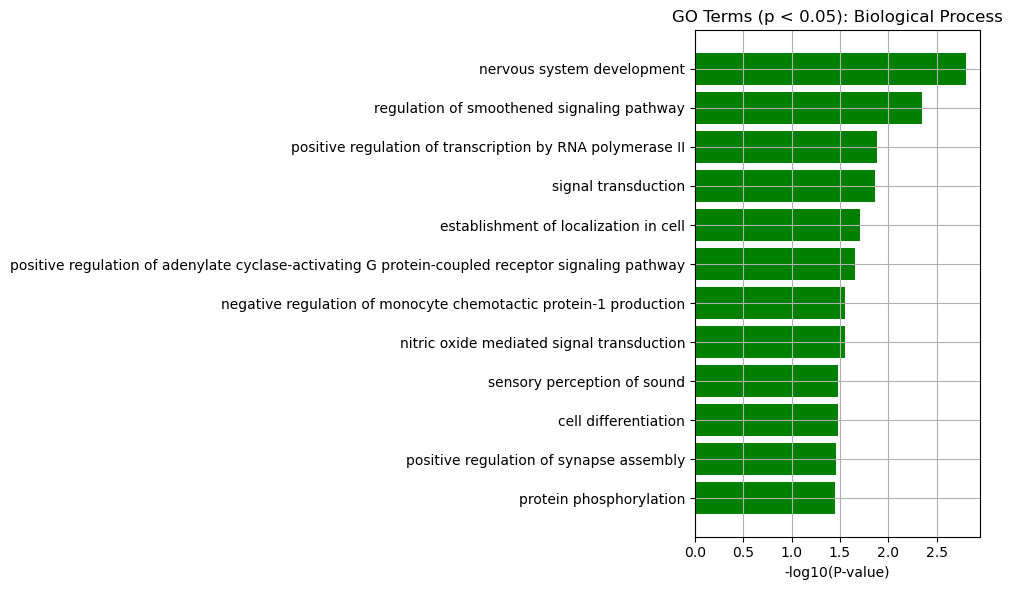

In [19]:
plot_filtered_terms(filtered_bp, "Biological Process", "green")

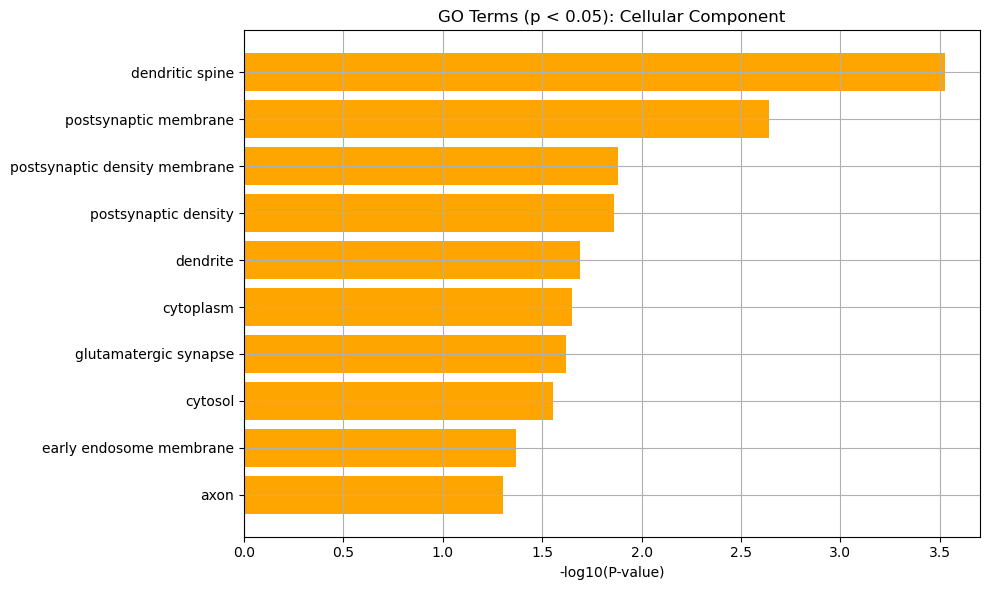

In [20]:
plot_filtered_terms(filtered_cc, "Cellular Component", "orange")

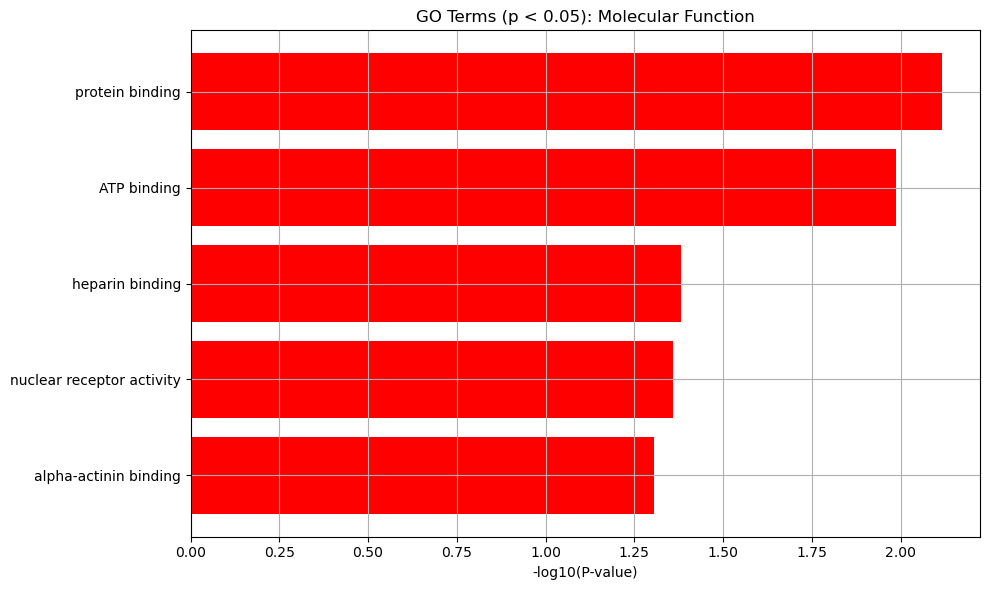

In [21]:
plot_filtered_terms(filtered_mf, "Molecular Function", "red")

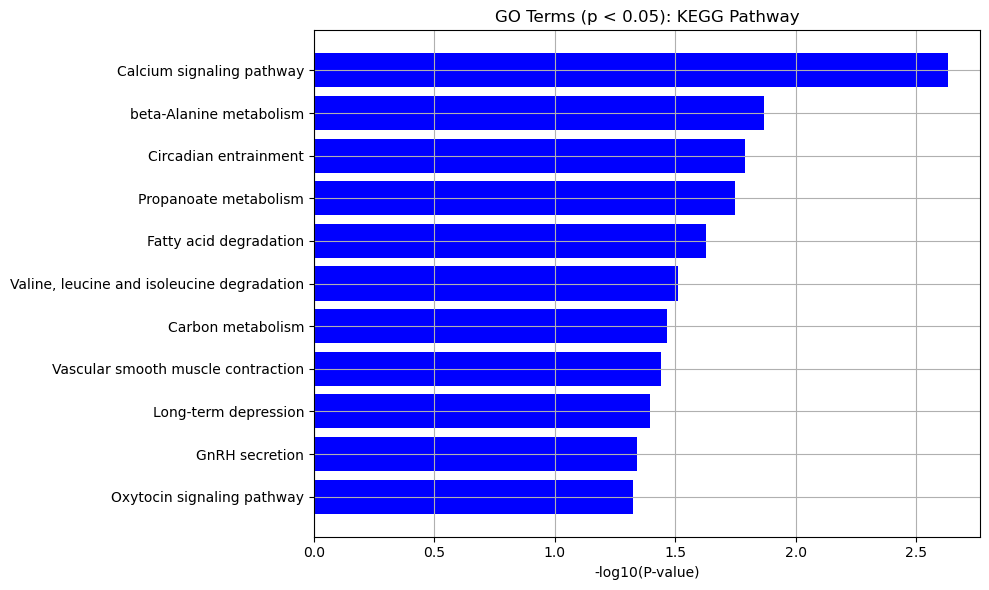

In [22]:
plot_filtered_terms(filtered_kegg, "KEGG Pathway", "blue")

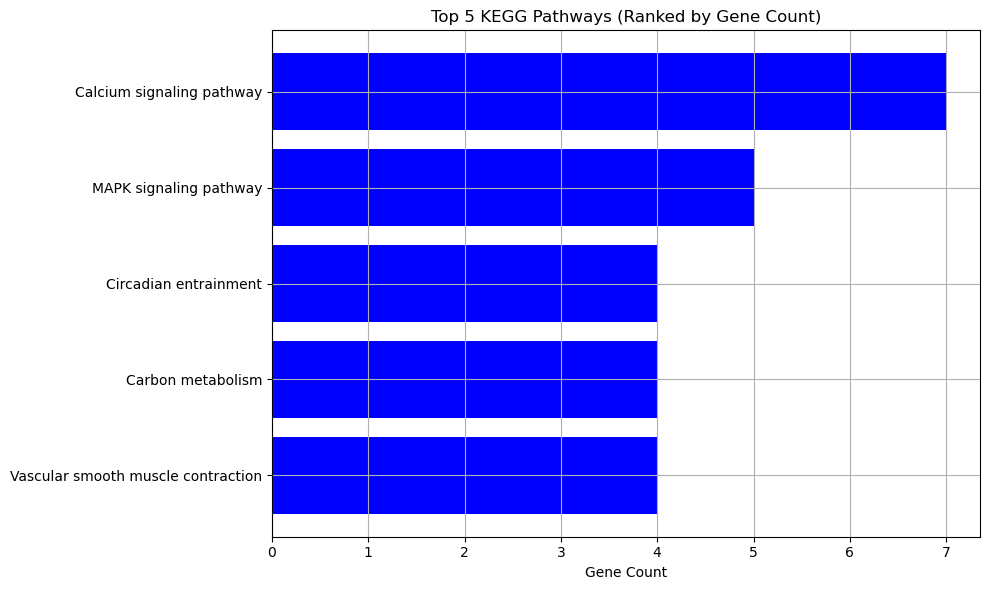

In [23]:
# Correcting the "Count" column name issue
top_n = 5
top_kegg_count = kegg_df.sort_values(by="Count", ascending=False).head(top_n).copy()
top_kegg_count["Category_Label"] = "KEGG"
top_kegg_count = top_kegg_count[["Term", "Count", "PValue", "Genes", "Category_Label"]]

# Plot: KEGG Pathways ranked by Count
plt.figure(figsize=(10, 6))
plt.barh(top_kegg_count["Term"], top_kegg_count["Count"], color="blue")
plt.xlabel('Gene Count')
plt.title('Top 5 KEGG Pathways (Ranked by Gene Count)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.grid(True)
plt.show()

C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_23332\3223140620.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


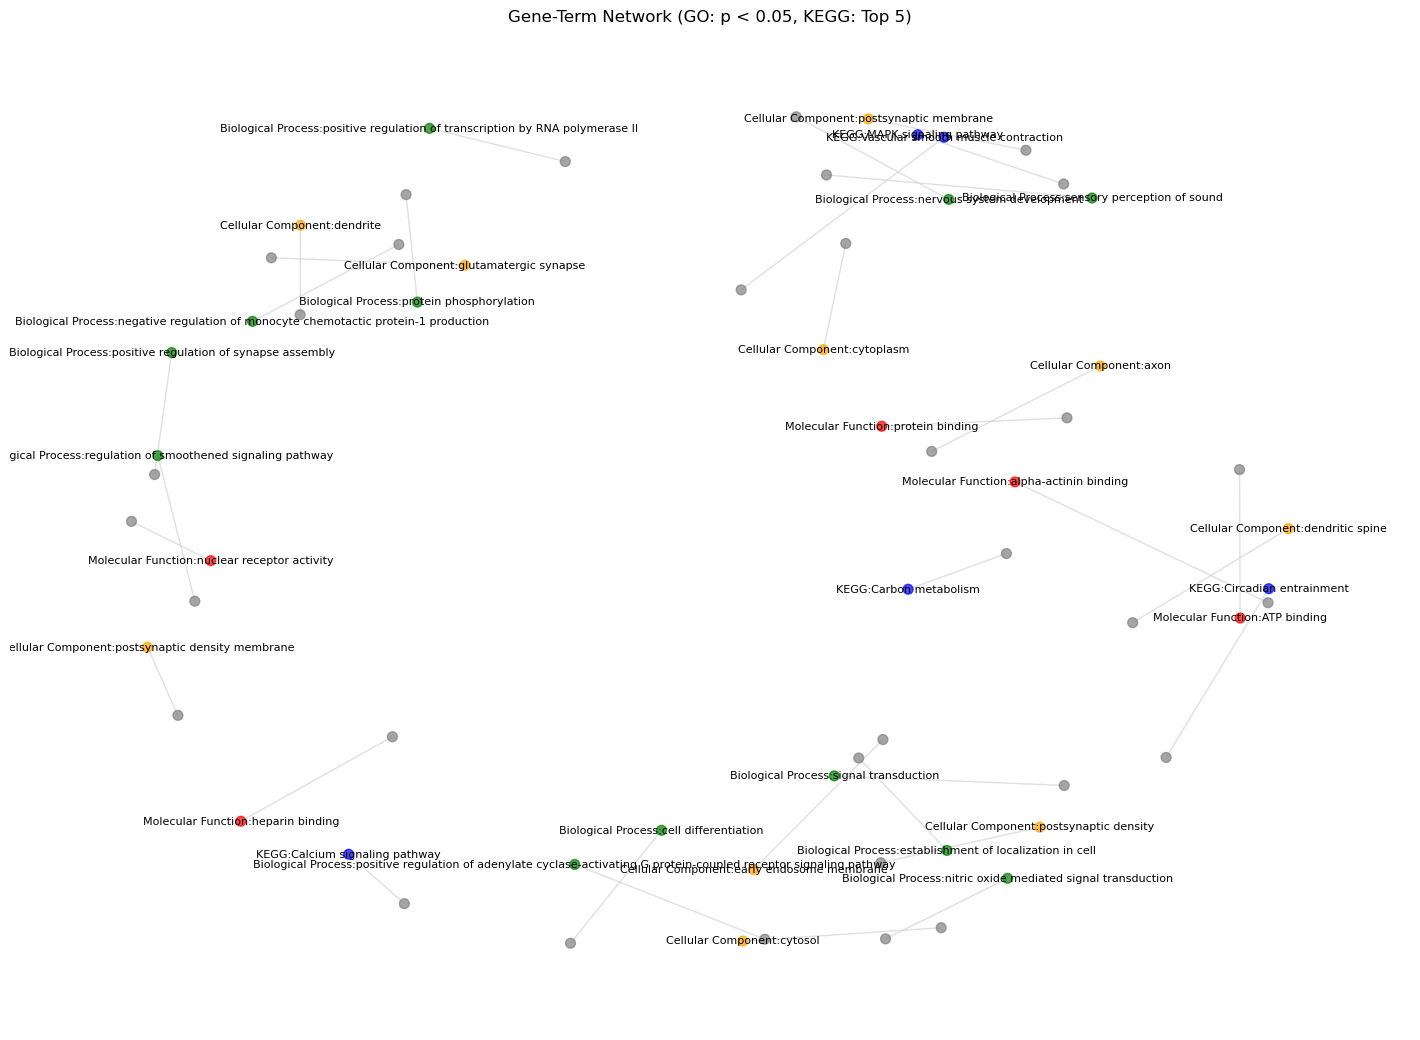

In [24]:
combined_filtered = pd.concat([filtered_bp, filtered_cc, filtered_mf, top_kegg_count])
colors = {"KEGG": "blue", "Biological Process": "green", "Cellular Component": "orange", "Molecular Function": "red"}

G = nx.Graph()
for _, row in combined_filtered.iterrows():
    term = f"{row['Category_Label']}:{row['Term'].split('~')[-1]}"
    genes = row["Genes"].split(", ")
    for gene in genes:
        G.add_node(gene, type='gene')
        G.add_node(term, type='term', color=row["Category_Label"])
        G.add_edge(gene, term)


plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.5, seed=42)
node_colors = [colors.get(G.nodes[n].get("color", ""), "gray") for n in G.nodes()]
nx.draw(G, pos, with_labels=False, node_size=50, node_color=node_colors, edge_color='lightgray', alpha=0.7)
term_nodes = [n for n in G.nodes() if G.nodes[n].get("type") == "term"]
nx.draw_networkx_labels(G, pos, labels={n: n for n in term_nodes}, font_size=8)
plt.title("Gene-Term Network (GO: p < 0.05, KEGG: Top 5)")
plt.axis("off")
plt.tight_layout()
plt.show()

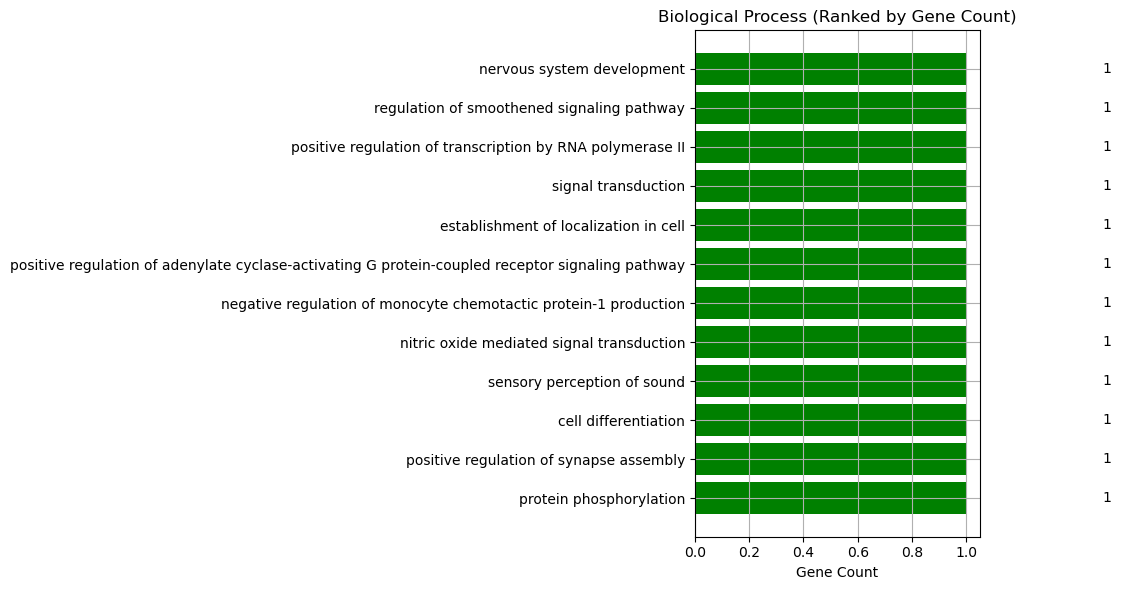

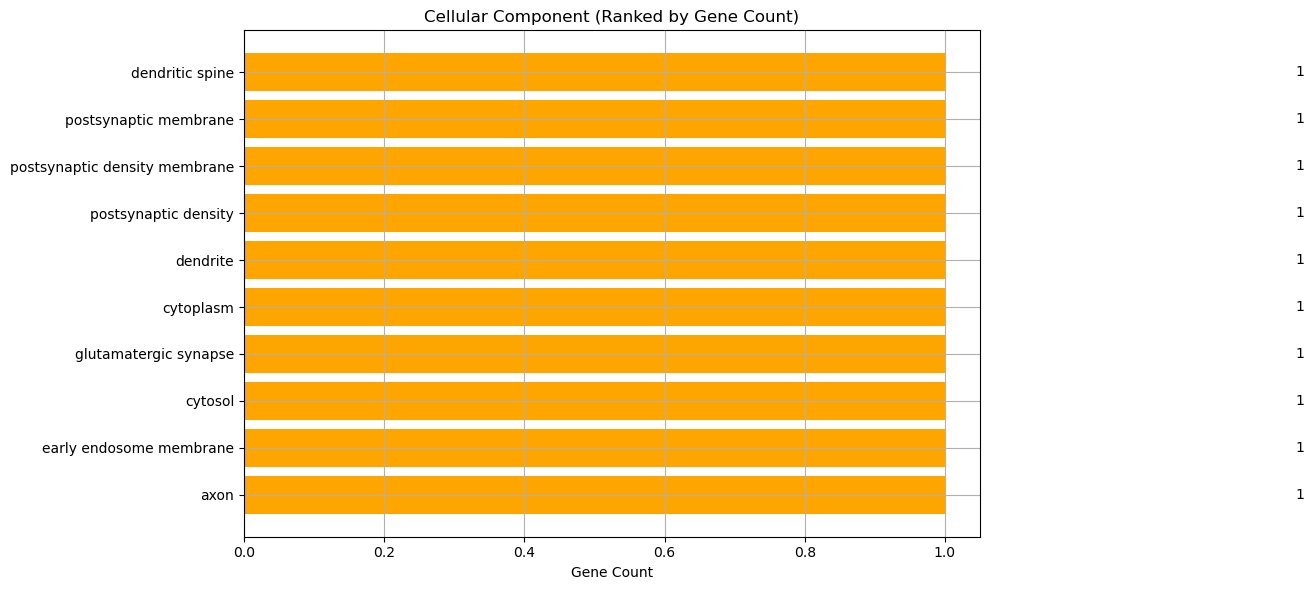

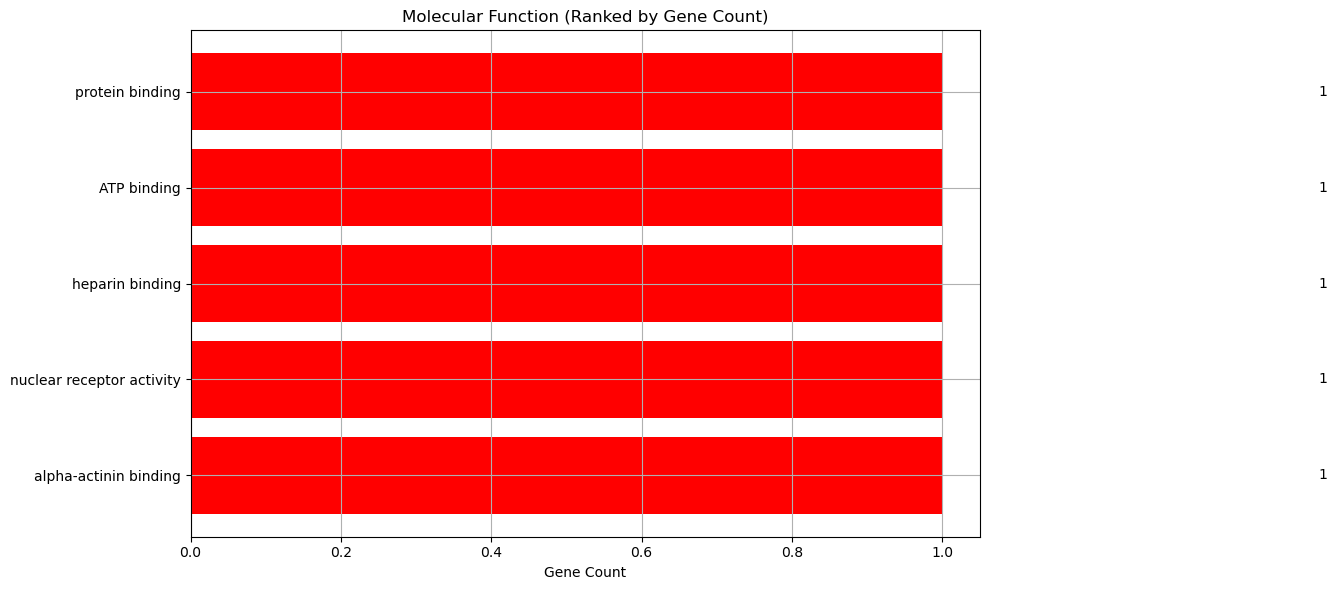

In [25]:
# Plotting function with gene count annotation
def plot_by_gene_count_annotated(df, title, color):
    df["GeneCount"] = df["Genes"].apply(lambda x: len(x.split(", ")))
    df_sorted = df.sort_values(by="GeneCount", ascending=False)
    plt.figure(figsize=(10, max(6, len(df_sorted) * 0.4)))
    bars = plt.barh(df_sorted["Term"], df_sorted["GeneCount"], color=color)
    plt.xlabel('Gene Count')
    plt.title(f'{title} (Ranked by Gene Count)')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.grid(True)

    # Annotate each bar with its gene count
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.5, bar.get_y() + bar.get_height()/2, str(int(width)), va='center')

    plt.show()

# Replot each GO category with annotation
plot_by_gene_count_annotated(filtered_bp, "Biological Process", "green")
plot_by_gene_count_annotated(filtered_cc, "Cellular Component", "orange")
plot_by_gene_count_annotated(filtered_mf, "Molecular Function", "red")



In [27]:
import os, math, textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ====== 사용자 경로 설정 ======
bp_path   = '../../03_GWAS_Pure/14_Regression_local/08_001_1e6_10_LT_GOTERM_BP_DIRECT.txt'
cc_path   = '../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_GOTERM_CC_DIRECT.txt'
mf_path   = '../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_GOTERM_MF_DIRECT.txt'
kegg_path = '../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_KEGG_PATHWAY.txt'

out_dir = '../../03_GWAS_Pure/14_Regression_local/GO_KEGG'
os.makedirs(out_dir, exist_ok=True)

TOP_N   = 12        # 그림에 표시할 항목 수
FDR_CUT = 0.10      # 저널 기준에 자주 쓰이는 FDR 컷
TERM_WRAP = 42      # y축 라벨 줄바꿈 폭

# ====== 유틸 ======
def bh_fdr(pvals: pd.Series) -> pd.Series:
    """Benjamini–Hochberg FDR (의존 라이브러리 없이)."""
    p = pvals.astype(float).values
    n = len(p)
    order = np.argsort(p)
    ranks = np.empty_like(order); ranks[order] = np.arange(1, n+1)
    fdr = p * n / ranks
    # 누적 최소치 보정
    fdr_sorted = np.minimum.accumulate(np.flip(np.sort(fdr)))
    fdr_adj = np.empty_like(fdr); fdr_adj[order] = np.flip(fdr_sorted)
    return pd.Series(np.clip(fdr_adj, 0, 1), index=pvals.index)

def tidy_terms(df: pd.DataFrame, category: str) -> pd.DataFrame:
    """
    DAVID 출력 표준화:
      - Term, PValue, Genes, Count, List.Total(있으면) 사용
      - GeneRatio = Count / List.Total (없으면 Genes 길이로 근사)
    """
    cols = {c.lower(): c for c in df.columns}
    # 필수 열 이름 스냅샷
    term_col = cols.get('term', 'Term')
    p_col    = cols.get('pvalue', 'PValue')
    genes_c  = cols.get('genes', 'Genes')
    count_c  = cols.get('count', 'Count') if 'count' in cols else None
    total_c  = cols.get('list.total', 'List.Total') if 'list.total' in cols else None

    df2 = df.copy()
    # 용어 정리: "GO:XXXX ~ name" -> name 만 남기고 적당히 줄바꿈
    def clean_term(x: str) -> str:
        x = str(x)
        if '~' in x:
            x = x.split('~', 1)[1]
        x = x.replace('_', ' ')
        return "\n".join(textwrap.wrap(x, TERM_WRAP))

    df2['Category'] = category
    df2['Term_clean'] = df2[term_col].map(clean_term)
    df2['PValue'] = pd.to_numeric(df2[p_col], errors='coerce')
    # 유전자 수 계산
    if count_c and count_c in df2.columns:
        df2['Count'] = pd.to_numeric(df2[count_c], errors='coerce')
    else:
        df2['Count'] = df2[genes_c].fillna('').apply(lambda s: 0 if s=='' else len(str(s).split(',')))
    # 배경 크기
    if total_c and total_c in df2.columns:
        df2['ListTotal'] = pd.to_numeric(df2[total_c], errors='coerce')
    else:
        # total 정보가 없으면 최고 count의 1.5배를 background 근사(보수적으로)
        df2['ListTotal'] = max(df2['Count'].max(), 1) * 1.5
    df2['GeneRatio'] = df2['Count'] / df2['ListTotal']
    # FDR
    df2 = df2.dropna(subset=['PValue']).reset_index(drop=True)
    df2['FDR'] = bh_fdr(df2['PValue'])
    df2['neglog10FDR'] = -np.log10(df2['FDR'].replace(0, np.nextafter(0, 1)))
    return df2

def select_top(df: pd.DataFrame, top_n: int, fdr_cut: float) -> pd.DataFrame:
    filtered = df[df['FDR'] <= fdr_cut].copy()
    if filtered.empty:
        # 컷을 통과 못하면 PValue 기준 상위 표시
        filtered = df.nsmallest(top_n, 'PValue').copy()
    else:
        filtered = filtered.sort_values(['FDR','PValue']).head(top_n)
    return filtered

def barplot_panel(df_top: pd.DataFrame, title: str, outbase: str):
    dfp = df_top.sort_values('neglog10FDR', ascending=True)
    fig, ax = plt.subplots(figsize=(8, max(4, 0.35*len(dfp)+1)))
    ax.barh(dfp['Term_clean'], dfp['neglog10FDR'])
    ax.set_xlabel(r'$-\log_{10}(\mathrm{FDR})$')
    ax.set_title(title, pad=10)
    ax.grid(True, axis='x', linestyle='--', linewidth=0.5)
    plt.tight_layout()
    fig.savefig(outbase + '_bar.svg')
    fig.savefig(outbase + '_bar.pdf')
    fig.savefig(outbase + '_bar.png', dpi=400)
    plt.close(fig)

def dotplot_panel(df_top: pd.DataFrame, title: str, outbase: str):
    dfp = df_top.sort_values('neglog10FDR', ascending=True)
    y = np.arange(len(dfp))
    sizes = 20 + 180 * (dfp['Count'] / max(dfp['Count'].max(), 1))
    fig, ax = plt.subplots(figsize=(8.5, max(4, 0.40*len(dfp)+1)))
    sc = ax.scatter(dfp['neglog10FDR'], dfp['Term_clean'], s=sizes, c=dfp['GeneRatio'], cmap=None)
    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label('Gene ratio')
    ax.set_xlabel(r'$-\log_{10}(\mathrm{FDR})$')
    ax.set_title(title, pad=10)
    ax.grid(True, axis='x', linestyle='--', linewidth=0.5)
    plt.tight_layout()
    fig.savefig(outbase + '_dot.svg')
    fig.savefig(outbase + '_dot.pdf')
    fig.savefig(outbase + '_dot.png', dpi=400)
    plt.close(fig)

def run_one(path, category, out_prefix):
    df = standardize_david_columns(pd.read_csv(path, sep="\t"))
    tidy = tidy_terms(df, category)
    tidy.to_csv(out_prefix + '_tidy.csv', index=False)
    top = select_top(tidy, TOP_N, FDR_CUT)
    # 저장용 표도 같이
    top[['Category','Term_clean','PValue','FDR','Count','GeneRatio']].to_csv(out_prefix + '_top.csv', index=False)
    title_bar = f'{category}: top terms (FDR ≤ {FDR_CUT:g} or best {TOP_N})'
    title_dot = f'{category}: enrichment (size=Count, color=GeneRatio)'
    barplot_panel(top, title_bar, out_prefix)
    dotplot_panel(top, title_dot, out_prefix)

# ====== 실행 ======
run_one(bp_path,   'GO: Biological Process',   os.path.join(out_dir, 'GO_BP'))
run_one(cc_path,   'GO: Cellular Component',   os.path.join(out_dir, 'GO_CC'))
run_one(mf_path,   'GO: Molecular Function',   os.path.join(out_dir, 'GO_MF'))
run_one(kegg_path, 'KEGG Pathway',             os.path.join(out_dir, 'KEGG'))

print("✅ Saved figures to:", out_dir)


✅ Saved figures to: ../../03_GWAS_Pure/14_Regression_local/GO_KEGG


In [28]:
import os, textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ====== 사용자 설정 ======
paths = {
    "BP": "../../03_GWAS_Pure/14_Regression_local/08_001_1e6_10_LT_GOTERM_BP_DIRECT.txt",
    "CC": "../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_GOTERM_CC_DIRECT.txt",
    "MF": "../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_GOTERM_MF_DIRECT.txt",
    "KEGG": "../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_KEGG_PATHWAY.txt"
}
out_dir = "../../03_GWAS_Pure/14_Regression_local/GO_KEGG"
os.makedirs(out_dir, exist_ok=True)

TOP_N = 16
TERM_WRAP = 40
FDR_CUT = 0.10


# ====== 유틸 ======
def bh_fdr(pvals: pd.Series) -> pd.Series:
    """Benjamini–Hochberg correction"""
    p = pvals.values
    n = len(p)
    order = np.argsort(p)
    ranked = np.empty_like(order)
    ranked[order] = np.arange(1, n + 1)
    fdr = p * n / ranked
    fdr = np.minimum.accumulate(fdr[::-1])[::-1]
    return np.clip(fdr, 0, 1)


def tidy_david(df, category):
    """DAVID 형식 정리"""
    df = df.copy()
    if "Term" not in df.columns:
        df.columns = [c.strip() for c in df.columns]
    df["Term_clean"] = df["Term"].apply(
        lambda x: "\n".join(textwrap.wrap(str(x).split("~")[-1], TERM_WRAP))
    )
    df["PValue"] = pd.to_numeric(df["PValue"], errors="coerce")
    df["Count"] = df["Genes"].fillna("").apply(lambda s: len(str(s).split(",")) if s else 0)
    df["GeneRatio"] = df["Count"] / max(df["Count"].max(), 1)
    df["FDR"] = bh_fdr(df["PValue"])
    df["neglog10FDR"] = -np.log10(df["FDR"].replace(0, np.nextafter(0, 1)))
    df["Category"] = category
    return df


def select_top(df):
    df_sig = df[df["FDR"] <= FDR_CUT]
    if df_sig.empty:
        return df.nsmallest(TOP_N, "PValue")
    return df_sig.sort_values(["FDR", "PValue"]).head(TOP_N)


# ====== 통합 Figure (bar + dot) ======
def plot_combined(df, title, out_prefix):
    df = df.sort_values("neglog10FDR", ascending=True)
    ylabels = df["Term_clean"]
    y_pos = np.arange(len(df))

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(14, max(4, 0.5 * len(df) + 2)), gridspec_kw={'width_ratios':[1,1.1]}
    )

    # --- Bar plot (왼쪽)
    ax1.barh(y_pos, df["neglog10FDR"], color="#3B8AC4")
    ax1.set_xlabel(r"$- \log_{10}(\mathrm{FDR})$", fontsize=11)
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(ylabels, fontsize=9)
    ax1.invert_yaxis()
    ax1.set_title(f"{title}\n(Top {TOP_N}, FDR ≤ {FDR_CUT})", fontsize=12, pad=10)
    ax1.grid(axis='x', linestyle='--', alpha=0.5)

    # --- Dot plot (오른쪽)
    sc = ax2.scatter(
        df["neglog10FDR"], y_pos,
        s=40 + 220 * df["GeneRatio"],
        c=df["Count"], cmap="plasma", edgecolor="k", alpha=0.9
    )
    ax2.set_xlabel(r"$- \log_{10}(\mathrm{FDR})$", fontsize=11)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels([])
    ax2.grid(axis='x', linestyle='--', alpha=0.5)
    cbar = plt.colorbar(sc, ax=ax2)
    cbar.set_label("Gene count", fontsize=10)
    ax2.set_title("Dot plot (size = Gene ratio, color = Count)", fontsize=11)

    fig.tight_layout()
    fig.savefig(out_prefix + "_combined.svg")
    fig.savefig(out_prefix + "_combined.pdf")
    fig.savefig(out_prefix + "_combined.png", dpi=400)
    plt.close(fig)

titles = {
    "BP": "GO: Biological Process (Top 12 enriched terms, FDR ≤ 0.1)",
    "CC": "GO: Cellular Component (Top 10 enriched terms, FDR ≤ 0.1)",
    "MF": "GO: Molecular Function (Top 5 enriched terms, FDR ≤ 0.1)",
    "KEGG": "KEGG Pathway Enrichment (Top 12 enriched pathways, FDR ≤ 0.1)"
}


# ====== 실행 ======
for label, path in paths.items():
    df = standardize_david_columns(pd.read_csv(path, sep="\t"))
    tidy = tidy_david(df, label)
    top = select_top(tidy)
    out_prefix = os.path.join(out_dir, label)
    plot_combined(top, titles[label], out_prefix)

print(f"✅ Figures saved to {out_dir}")


✅ Figures saved to ../../03_GWAS_Pure/14_Regression_local/GO_KEGG


In [29]:
import os, textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ====== 사용자 설정 ======
paths = {
    "BP": "../../03_GWAS_Pure/14_Regression_local/08_001_1e6_10_LT_GOTERM_BP_DIRECT.txt",
    "CC": "../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_GOTERM_CC_DIRECT.txt",
    "MF": "../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_GOTERM_MF_DIRECT.txt",
    "KEGG": "../../03_GWAS_Pure/14_Regression_local/08_001_1E6_10_LT_KEGG_PATHWAY.txt"
}
out_dir = "../../03_GWAS_Pure/14_Regression_local/GO_KEGG"
os.makedirs(out_dir, exist_ok=True)

TOP_N   = 25              # 그릴 최대 개수(제목 표시는 실제 FDR≤cut 개수로)
TERM_WRAP = 40
FDR_CUT  = 0.10

# 제목 앞부분과 단어(terms/pathways) 매핑
title_head = {
    "BP":   "GO: Biological Process",
    "CC":   "GO: Cellular Component",
    "MF":   "GO: Molecular Function",
    "KEGG": "KEGG Pathway Enrichment",
}
noun_word = {"KEGG": "pathways", "BP": "terms", "CC": "terms", "MF": "terms"}

# ====== 유틸 ======
def bh_fdr(pvals: pd.Series) -> pd.Series:
    """Benjamini–Hochberg correction"""
    p = pvals.values
    n = len(p)
    order = np.argsort(p)
    ranks = np.empty_like(order)
    ranks[order] = np.arange(1, n+1)
    fdr = p * n / ranks
    fdr = np.minimum.accumulate(fdr[::-1])[::-1]
    return np.clip(fdr, 0, 1)

def tidy_david(df, category):
    """DAVID 형식 정리"""
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    df["Term_clean"] = df["Term"].apply(lambda x: "\n".join(textwrap.wrap(str(x).split("~")[-1], TERM_WRAP)))
    df["PValue"] = pd.to_numeric(df["PValue"], errors="coerce")
    df["Count"] = df["Genes"].fillna("").apply(lambda s: len(str(s).split(",")) if s else 0)
    df["GeneRatio"] = df["Count"] / max(df["Count"].max(), 1)
    df["FDR"] = bh_fdr(df["PValue"])
    df["neglog10FDR"] = -np.log10(df["FDR"].replace(0, np.nextafter(0,1)))
    df["Category"] = category
    return df

def select_top(df):
    """FDR≤cut 개수(n_sig)를 함께 반환. 그릴 데이터는 TOP_N으로 제한."""
    n_sig = int((df["FDR"] <= FDR_CUT).sum())
    if n_sig > 0:
        draw_df = df[df["FDR"] <= FDR_CUT].sort_values(["FDR","PValue"]).head(TOP_N)
    else:
        # 유의 항목이 없으면 P값 기준 상위 TOP_N 사용 (제목에는 0 표시)
        draw_df = df.nsmallest(TOP_N, "PValue")
    return draw_df, n_sig

# ====== 통합 Figure (bar + dot) ======
def plot_combined(df, cat_key, n_sig, out_prefix):
    df = df.sort_values("neglog10FDR", ascending=True)
    ylabels = df["Term_clean"]
    y_pos = np.arange(len(df))

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(14, max(4, 0.5*len(df)+2)),
        gridspec_kw={'width_ratios':[1,1.1]}
    )

    # --- Bar plot
    ax1.barh(y_pos, df["neglog10FDR"], color="#3B8AC4")
    ax1.set_xlabel(r"$- \log_{10}(\mathrm{FDR})$", fontsize=11)
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(ylabels, fontsize=9)
    ax1.invert_yaxis()
    # 동적 제목: Top {n_sig} enriched terms/pathways
    noun = noun_word[cat_key]
    ax1.set_title(f"{title_head[cat_key]} ({n_sig} enriched {noun}, [FDR ≤ {FDR_CUT}])",
                  fontsize=12, pad=10)
    ax1.grid(axis='x', linestyle='--', alpha=0.5)

    # --- Dot plot
    sc = ax2.scatter(
        df["neglog10FDR"], y_pos,
        s=40 + 220*df["GeneRatio"],
        c=df["Count"], cmap="plasma", edgecolor="k", alpha=0.9
    )
    ax2.set_xlabel(r"$- \log_{10}(\mathrm{FDR})$", fontsize=11)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels([])  # 좌/우 정렬용
    ax2.grid(axis='x', linestyle='--', alpha=0.5)
    cbar = plt.colorbar(sc, ax=ax2)
    cbar.set_label("Gene count", fontsize=10)
    ax2.set_title("Dot plot (size = Gene ratio, color = Count)", fontsize=11)

    fig.tight_layout()
    fig.savefig(out_prefix + "_combined.svg")
    fig.savefig(out_prefix + "_combined.pdf")
    fig.savefig(out_prefix + "_combined.png", dpi=400)
    plt.close(fig)

# ====== 실행 ======
for key, path in paths.items():
    df_raw = standardize_david_columns(pd.read_csv(path, sep="\t"))
    tidy = tidy_david(df_raw, key)
    top_df, n_sig = select_top(tidy)        # n_sig = FDR≤cut 실제 개수
    out_prefix = os.path.join(out_dir, key)
    plot_combined(top_df, key, n_sig, out_prefix)


print(f"✅ Figures saved to {out_dir}")


✅ Figures saved to ../../03_GWAS_Pure/14_Regression_local/GO_KEGG


In [30]:
# 이전에 추가하신 standardize_david_columns() 함수가 이미 있다는 전제하에

kegg_df = standardize_david_columns(pd.read_csv(paths["KEGG"], sep="\t"))

# Term이 "circadian entrainment"인 행 찾기 (Term에 KEGG ID 접두어가 붙어있을 수 있어 부분일치로 검색, 대소문자 무시)
circadian_row = kegg_df[kegg_df["Term"].str.contains("circadian entrainment", case=False, na=False)]

# Gene ID 목록 추출 (User Ids -> Genes로 표준화된 컬럼, 쉼표로 구분되어 있음)
circadian_gene_ids = circadian_row["Genes"].iloc[0].split(",")
circadian_gene_ids = [g.strip() for g in circadian_gene_ids]

print(f"Circadian entrainment 유전자 개수: {len(circadian_gene_ids)}")
print(circadian_gene_ids)

Circadian entrainment 유전자 개수: 4
['ENSCAFG00000014739', 'ENSCAFG00000016051', 'ENSCAFG00000005760', 'ENSCAFG00000009820']


In [31]:
matched_path = "J:/01_lab_lee/03_GWAS_Pure/14_Regression_local/06_Matched_Genes_001_1e6_10_LT.csv"
matched_df = pd.read_csv(matched_path)

# 앞서 뽑은 circadian entrainment 유전자 ID로 필터링
circadian_snps = matched_df[matched_df["gene_id"].isin(circadian_gene_ids)]

print(f"Circadian entrainment 관련 SNP 개수: {len(circadian_snps)}")
print(circadian_snps)

# 저장(선택)
out_path = "J:/01_lab_lee/03_GWAS_Pure/14_Regression_local/06_CircadianEntrainment_SNPs.csv"
circadian_snps.to_csv(out_path, index=False)
print(f"✅ 저장 완료: {out_path}")

Circadian entrainment 관련 SNP 개수: 5
     CHR              SNP       POS             gene_id
78    24  24:12787767:A:G  12787767  ENSCAFG00000005760
142   26  26:13787793:A:G  13787793  ENSCAFG00000009820
204    5   5:25529184:C:T  25529184  ENSCAFG00000014739
211   27  27:44543118:A:T  44543118  ENSCAFG00000016051
215   24  24:12787779:T:C  12787779  ENSCAFG00000005760
✅ 저장 완료: J:/01_lab_lee/03_GWAS_Pure/14_Regression_local/06_CircadianEntrainment_SNPs.csv
